# Task 3: Bank term deposit model

## Stage 1: Understanding the Problem

A bank wants to sell term deposits to its clients. The call centre can call only 10% of the clients.

Our model must give each client a score. Clients with higher scores are more likely to say yes.

I use Average Precision (AP) as the main metric because the bank wants to find positive clients near the top of the list. I also use ROC-AUC to measure how well the model ranks positive and negative clients.

Accuracy is not enough because most clients say no. A model can have high accuracy and still find very few clients who say yes.

In [22]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 2345
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SEED:", SEED)

Python: 3.13.2
NumPy: 2.3.4
Pandas: 2.3.3
Matplotlib: 3.10.7
Scikit-learn: 1.7.2
SEED: 2345


## Stage 2: Loading the Data

I load the training and test data. The training data has the target column called `y`, but the test data does not have the answers.

I compare the column names before building the model. I use only the features that are available in the test data, without the `id` column.

The `duration` column must not be used if it is missing from the test data. It shows the length of a call, so it is not known before the call starts.

In [23]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("Only in train:", sorted(set(train.columns) - set(test.columns)))
print("Only in test:", sorted(set(test.columns) - set(train.columns)))

assert "y" in train.columns, "The target column y is missing."
assert "id" in test.columns, "The id column is missing."

feature_cols = [c for c in test.columns if c != "id"]

missing_features = set(feature_cols) - set(train.columns)
assert not missing_features, f"Missing training features: {missing_features}"

X = train[feature_cols].copy()
y = train["y"].astype(str).str.lower().isin(["yes", "1"]).astype(int)

print("Number of features:", len(feature_cols))
print("Target values:")
print(y.value_counts())

X.head()

Train shape: (32940, 22)
Test shape: (8236, 20)
Only in train: ['duration', 'y']
Only in test: []
Number of features: 19
Target values:
y
0    29229
1     3711
Name: count, dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,39,management,single,basic.9y,unknown,yes,no,telephone,may,tue,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0
1,32,admin.,single,university.degree,no,yes,no,cellular,aug,mon,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1
2,41,technician,married,high.school,no,no,yes,cellular,aug,fri,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1
3,39,admin.,married,professional.course,no,yes,yes,telephone,may,wed,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,wed,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1


Column Comparison: The code shows which columns are different in the training and test data. I use only the common input features that are available in the test data. This helps prevent data leakage and makes the saved model ready for new data.

I will write the exact missing column names after I run the code.

## Stage 3: Exploring the Data

First, I check how many clients say yes and no. I also calculate the accuracy of a model that always predicts no.

Next, I check missing values, the value `unknown`, and the special value 999 in `pdays`. I also study the row order and compare some features with the target.

These checks help me understand the data before training the models.

In [24]:
print("Target counts:")
print(y.value_counts())

print("\nTarget shares:")
print(y.value_counts(normalize=True).round(4))

yes_rate = y.mean()
always_no_accuracy = (y == 0).mean()

print("Yes rate:", round(yes_rate, 4))
print("Always-no accuracy:", round(always_no_accuracy, 4))

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols_all = X.select_dtypes(include=np.number).columns.tolist()

print("\nUnknown values:")
for col in cat_cols:
    count = X[col].astype(str).eq("unknown").sum()
    if count > 0:
        print(f"{col}: {count} ({count / len(X):.2%})")

print("\nReal missing values:")
print(X.isna().sum()[X.isna().sum() > 0])

if "pdays" in X.columns:
    count_999 = X["pdays"].eq(999).sum()
    print("pdays == 999:", count_999)
    print("pdays == 999 share:", round(count_999 / len(X), 4))

Target counts:
y
0    29229
1     3711
Name: count, dtype: int64

Target shares:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64
Yes rate: 0.1127
Always-no accuracy: 0.8873

Unknown values:
job: 275 (0.83%)
marital: 64 (0.19%)
education: 1401 (4.25%)
default: 6871 (20.86%)
housing: 794 (2.41%)
loan: 794 (2.41%)

Real missing values:
Series([], dtype: int64)
pdays == 999: 31694
pdays == 999 share: 0.9622


Checking the Row Order: I check whether the row number is related to `euribor3m`. This feature describes an economic interest rate.

If the values change in a clear pattern, the rows may contain some time order. However, this check alone cannot prove that the rows are sorted by date. I will describe only what I can see in the data.

Correlation with row number: 0.002


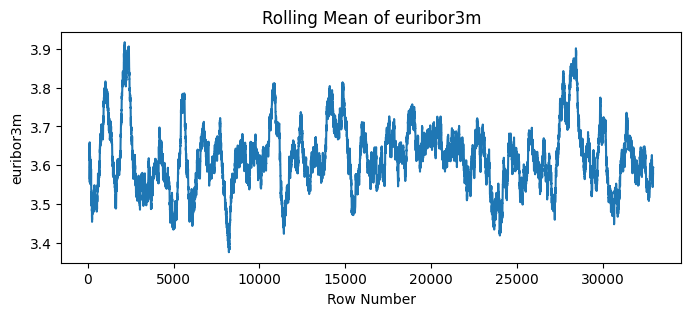

In [25]:
if "euribor3m" in X.columns:
    row_corr = pd.Series(np.arange(len(X))).corr(X["euribor3m"])

    print("Correlation with row number:", round(row_corr, 4))

    X["euribor3m"].rolling(500, min_periods=100).mean().plot(
        figsize=(8, 3)
    )
    plt.title("Rolling Mean of euribor3m")
    plt.xlabel("Row Number")
    plt.ylabel("euribor3m")
    plt.show()
else:
    print("The euribor3m column is not available.")

Features and the Target: I compare the share of yes answers for different previous campaign results. I also compare `euribor3m` for clients who said yes and no.

The printed numbers help me understand the plots. These relationships do not prove that a feature causes the client to say yes.

Yes rate by poutcome:
poutcome
nonexistent    0.0881
failure        0.1403
success        0.6478
Name: y, dtype: float64


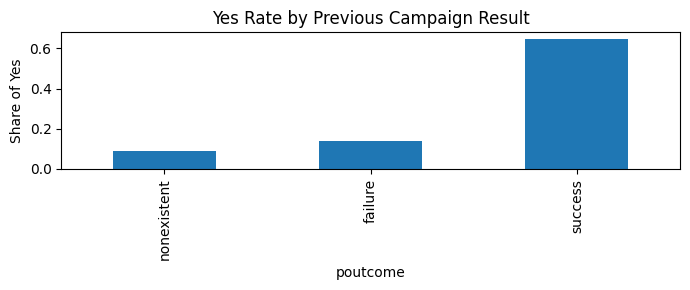

Mean euribor3m for no: 3.812
Mean euribor3m for yes: 2.119


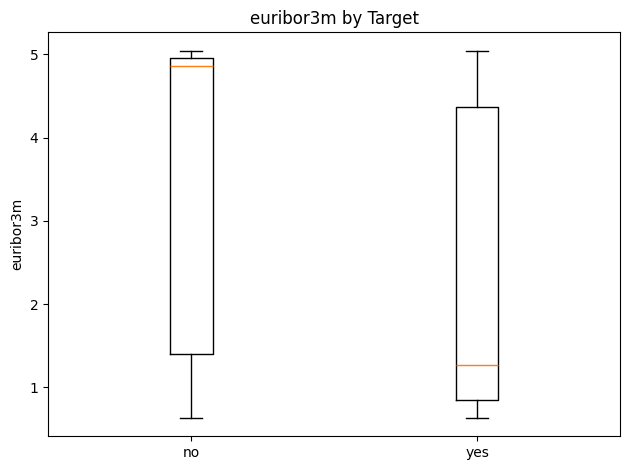

Numeric correlations with y:
nr.employed      -0.3557
pdays            -0.3285
euribor3m        -0.3084
emp.var.rate     -0.2986
cons.price.idx   -0.1341
campaign         -0.0654
age               0.0325
cons.conf.idx     0.0583
previous          0.2319
dtype: float64


In [26]:
if "poutcome" in X.columns:
    yes_rate_by_outcome = y.groupby(X["poutcome"]).mean().sort_values()

    print("Yes rate by poutcome:")
    print(yes_rate_by_outcome.round(4))

    yes_rate_by_outcome.plot(kind="bar", figsize=(7, 3))
    plt.title("Yes Rate by Previous Campaign Result")
    plt.ylabel("Share of Yes")
    plt.tight_layout()
    plt.show()

if "euribor3m" in X.columns:
    no_mean = X.loc[y == 0, "euribor3m"].mean()
    yes_mean = X.loc[y == 1, "euribor3m"].mean()

    print("Mean euribor3m for no:", round(no_mean, 4))
    print("Mean euribor3m for yes:", round(yes_mean, 4))

    plt.boxplot([
        X.loc[y == 0, "euribor3m"].dropna(),
        X.loc[y == 1, "euribor3m"].dropna()
    ])
    plt.xticks([1, 2], ["no", "yes"])
    plt.title("euribor3m by Target")
    plt.ylabel("euribor3m")
    plt.tight_layout()
    plt.show()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Numeric correlations with y:")
print(X[numeric_cols].corrwith(y).sort_values().round(4))

## Stage 4: Validation Design

I keep 20% of the training data for the final test. I do not use this part when I compare or tune models.

I use the other 80% for five-fold StratifiedKFold validation. Each fold has a similar share of yes and no answers. This is useful because the target classes are not balanced.

I use the same folds to compare the models fairly.

In [27]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_tr, X_hold, y_tr, y_hold = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("Training part:", X_tr.shape)
print("Hold-out part:", X_hold.shape)
print("Yes share in training:", round(y_tr.mean(), 4))
print("Yes share in hold-out:", round(y_hold.mean(), 4))

Training part: (26352, 19)
Hold-out part: (6588, 19)
Yes share in training: 0.1127
Yes share in hold-out: 0.1126


## Stage 5: Data Preprocessing

I put the preprocessing steps inside a Pipeline. This means that the model learns the filling values, scaling values and categories from the training fold only.

For numerical features, I use the median and StandardScaler. For categorical features, I use OneHotEncoder.

I also compare two ways to handle `unknown` and two ways to handle `pdays = 999`. I use cross-validation to choose between these options.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

cat_cols = X_tr.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols_all = X_tr.select_dtypes(
    include=np.number
).columns.tolist()

num_cols = [c for c in num_cols_all if c != "pdays"]

def make_prep(unknown_as_missing=False, pdays_flag=True):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    if unknown_as_missing:
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(
                missing_values="unknown",
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])
    else:
        cat_pipe = OneHotEncoder(handle_unknown="ignore")

    if pdays_flag:
        pdays_imputer = SimpleImputer(
            missing_values=999,
            strategy="median",
            add_indicator=True
        )
    else:
        pdays_imputer = SimpleImputer(strategy="median")

    pdays_pipe = Pipeline([
        ("imputer", pdays_imputer),
        ("scaler", StandardScaler())
    ])

    transformers = [
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ]

    if "pdays" in X_tr.columns:
        transformers.append(("pdays", pdays_pipe, ["pdays"]))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

def make_pipe(model, **prep_options):
    return Pipeline([
        ("prep", make_prep(**prep_options)),
        ("model", model)
    ])

Checking Data Leakage: I fit a small model on the training part only. Then I check the mean learned by the scaler.

The scaler mean should match the mean of the training data. It should not be learned from the full dataset before validation. This is one check that supports my use of the Pipeline.

In [29]:
demo = make_pipe(
    LogisticRegression(max_iter=1000)
).fit(X_tr, y_tr)

if "age" in num_cols:
    scaler = demo.named_steps["prep"].named_transformers_["num"].named_steps["scaler"]
    age_index = num_cols.index("age")

    print("Scaler mean for age:", round(scaler.mean_[age_index], 4))
    print("Training mean for age:", round(X_tr["age"].mean(), 4))
else:
    print("The age column is not available in the numeric features.")

Scaler mean for age: 40.0536
Training mean for age: 40.0536


## Stage 6: Baseline Models

I start with two simple models. The first one predicts the most common class. The second one is Logistic Regression.

I measure accuracy, ROC-AUC and Average Precision with the same five folds. I use these results as a baseline for the other models.

Accuracy alone can be misleading because most clients say no.

In [30]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier

results = {}

def show(name, pipe):
    scores = cross_validate(
        pipe,
        X_tr,
        y_tr,
        cv=skf,
        scoring={
            "acc": "accuracy",
            "auc": "roc_auc",
            "ap": "average_precision"
        },
        n_jobs=-1
    )

    results[name] = {
        "acc": scores["test_acc"],
        "auc": scores["test_auc"],
        "ap": scores["test_ap"]
    }

    print(
        f"{name}: "
        f"Accuracy {scores['test_acc'].mean():.4f} "
        f"+/- {scores['test_acc'].std():.4f} | "
        f"AUC {scores['test_auc'].mean():.4f} "
        f"+/- {scores['test_auc'].std():.4f} | "
        f"AP {scores['test_ap'].mean():.4f} "
        f"+/- {scores['test_ap'].std():.4f}"
    )

def compare(a, b, metric="ap"):
    scores_a = results[a][metric]
    scores_b = results[b][metric]

    differences = scores_a - scores_b
    spread = max(scores_a.std(), scores_b.std())

    verdict = (
        "larger than fold spread"
        if abs(differences.mean()) > spread
        else "inside fold spread"
    )

    print(
        f"{a} - {b}: mean difference = "
        f"{differences.mean():+.4f}; "
        f"spread = {spread:.4f}; {verdict}"
    )

show(
    "Dummy",
    make_pipe(DummyClassifier(strategy="prior"))
)

show(
    "LogReg baseline",
    make_pipe(LogisticRegression(max_iter=1000))
)

Dummy: Accuracy 0.8873 +/- 0.0001 | AUC 0.5000 +/- 0.0000 | AP 0.1127 +/- 0.0001
LogReg baseline: Accuracy 0.8993 +/- 0.0031 | AUC 0.7912 +/- 0.0035 | AP 0.4470 +/- 0.0166


## Stage 7: Comparing Preprocessing Choices

I use Logistic Regression to compare different preprocessing choices.

First, I keep `unknown` as a separate category. Then I replace it with the most frequent category. I also compare two ways to handle `pdays = 999`.

I use the same cross-validation folds for all options. I choose an option based on the results, not on a guess.

In [31]:
show(
    "LR unknown kept pdays flag",
    make_pipe(
        LogisticRegression(max_iter=1000),
        unknown_as_missing=False,
        pdays_flag=True
    )
)

show(
    "LR unknown imputed pdays flag",
    make_pipe(
        LogisticRegression(max_iter=1000),
        unknown_as_missing=True,
        pdays_flag=True
    )
)

show(
    "LR unknown kept pdays raw",
    make_pipe(
        LogisticRegression(max_iter=1000),
        unknown_as_missing=False,
        pdays_flag=False
    )
)

compare(
    "LR unknown imputed pdays flag",
    "LR unknown kept pdays flag"
)

compare(
    "LR unknown kept pdays raw",
    "LR unknown kept pdays flag"
)

LR unknown kept pdays flag: Accuracy 0.8993 +/- 0.0031 | AUC 0.7912 +/- 0.0035 | AP 0.4470 +/- 0.0166
LR unknown imputed pdays flag: Accuracy 0.8996 +/- 0.0029 | AUC 0.7912 +/- 0.0038 | AP 0.4460 +/- 0.0173
LR unknown kept pdays raw: Accuracy 0.8989 +/- 0.0032 | AUC 0.7911 +/- 0.0035 | AP 0.4461 +/- 0.0164
LR unknown imputed pdays flag - LR unknown kept pdays flag: mean difference = -0.0010; spread = 0.0173; inside fold spread
LR unknown kept pdays raw - LR unknown kept pdays flag: mean difference = -0.0009; spread = 0.0166; inside fold spread


## Stage 8: Comparing Different Models

I compare five model types: Logistic Regression, KNN, Decision Tree, Random Forest and Linear SVM.

All models use the same preprocessing steps and cross-validation folds. This makes the comparison more fair.

I look mainly at Average Precision and also check ROC-AUC. I consider the fold variation before choosing a model.

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=SEED
    ),
    "Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=1
    ),
    "LinearSVM": LinearSVC(
        dual=False,
        random_state=SEED
    )
}

for name, model in models.items():
    show(name, make_pipe(model))

LogReg: Accuracy 0.8993 +/- 0.0031 | AUC 0.7912 +/- 0.0035 | AP 0.4470 +/- 0.0166
KNN: Accuracy 0.8982 +/- 0.0018 | AUC 0.7628 +/- 0.0045 | AP 0.4088 +/- 0.0085
Tree: Accuracy 0.8994 +/- 0.0028 | AUC 0.7727 +/- 0.0065 | AP 0.4018 +/- 0.0121
Forest: Accuracy 0.9001 +/- 0.0025 | AUC 0.7914 +/- 0.0063 | AP 0.4601 +/- 0.0137
LinearSVM: Accuracy 0.8989 +/- 0.0028 | AUC 0.7874 +/- 0.0053 | AP 0.4427 +/- 0.0155


## Stage 9: Hyperparameter Tuning

I use GridSearchCV to find better settings for four models. I use Average Precision as the scoring metric because the bank needs a good ranking of clients.

The search uses only the training part and the same five folds. I do not use the hold-out data for tuning.

I print the best settings and compare the tuned models with the baseline results.

In [33]:
from sklearn.model_selection import GridSearchCV

searches = {
    "LogReg": (
        LogisticRegression(max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10]}
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [15, 50, 100]}
    ),
    "Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {
            "model__max_depth": [3, 5, 8],
            "model__min_samples_leaf": [20, 100]
        }
    ),
    "Forest": (
        RandomForestClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=1
        ),
        {
            "model__max_depth": [6, 12, None],
            "model__min_samples_leaf": [5, 20]
        }
    )
}

best_pipes = {}
search_results = {}

for name, (model, grid) in searches.items():
    search = GridSearchCV(
        make_pipe(model),
        grid,
        scoring="average_precision",
        cv=skf,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_tr, y_tr)

    best_pipes[name] = search.best_estimator_
    search_results[name] = search

    print("\nModel:", name)
    print("Best parameters:", search.best_params_)
    print("Best CV AP:", round(search.best_score_, 4))

    show(name + "_tuned", search.best_estimator_)


Model: LogReg
Best parameters: {'model__C': 1}
Best CV AP: 0.447
LogReg_tuned: Accuracy 0.8993 +/- 0.0031 | AUC 0.7912 +/- 0.0035 | AP 0.4470 +/- 0.0166

Model: KNN
Best parameters: {'model__n_neighbors': 100}
Best CV AP: 0.423
KNN_tuned: Accuracy 0.8977 +/- 0.0023 | AUC 0.7821 +/- 0.0072 | AP 0.4230 +/- 0.0102

Model: Tree
Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 100}
Best CV AP: 0.4244
Tree_tuned: Accuracy 0.8990 +/- 0.0027 | AUC 0.7835 +/- 0.0041 | AP 0.4244 +/- 0.0133

Model: Forest
Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 5}
Best CV AP: 0.4617
Forest_tuned: Accuracy 0.8997 +/- 0.0024 | AUC 0.7986 +/- 0.0041 | AP 0.4617 +/- 0.0144


## Stage 10: Handling Class Imbalance

There are more clients who say no than clients who say yes. I test `class_weight="balanced"` for Logistic Regression, Decision Tree and Random Forest.

This option gives more weight to the smaller class during training. I compare AP and ROC-AUC with the tuned models without this option.

I keep the balanced version only if the results support this choice.

In [34]:
from sklearn.base import clone

for name in ["LogReg", "Tree", "Forest"]:
    balanced_pipe = clone(best_pipes[name]).set_params(
        model__class_weight="balanced"
    )

    balanced_name = name + "_balanced"

    show(balanced_name, balanced_pipe)

    compare(balanced_name, name + "_tuned", metric="ap")
    compare(balanced_name, name + "_tuned", metric="auc")

LogReg_balanced: Accuracy 0.8221 +/- 0.0054 | AUC 0.7920 +/- 0.0028 | AP 0.4412 +/- 0.0174
LogReg_balanced - LogReg_tuned: mean difference = -0.0058; spread = 0.0174; inside fold spread
LogReg_balanced - LogReg_tuned: mean difference = +0.0008; spread = 0.0035; inside fold spread
Tree_balanced: Accuracy 0.8169 +/- 0.0099 | AUC 0.7781 +/- 0.0024 | AP 0.4245 +/- 0.0129
Tree_balanced - Tree_tuned: mean difference = +0.0001; spread = 0.0133; inside fold spread
Tree_balanced - Tree_tuned: mean difference = -0.0054; spread = 0.0041; larger than fold spread
Forest_balanced: Accuracy 0.8575 +/- 0.0038 | AUC 0.7993 +/- 0.0038 | AP 0.4604 +/- 0.0162
Forest_balanced - Forest_tuned: mean difference = -0.0013; spread = 0.0162; inside fold spread
Forest_balanced - Forest_tuned: mean difference = +0.0008; spread = 0.0041; inside fold spread


## Stage 11: Results and Model Choice

I collect the results in one table and sort the models by Average Precision. I also check ROC-AUC and accuracy.

I compare the best models and look at the variation between folds. If the difference is small compared with the fold spread, I do not say that one model is clearly better.

I choose a model based on its results, speed and simplicity.

In [35]:
table = pd.DataFrame({
    name: {
        "AP mean": values["ap"].mean(),
        "AP std": values["ap"].std(),
        "AUC mean": values["auc"].mean(),
        "AUC std": values["auc"].std(),
        "Accuracy mean": values["acc"].mean()
    }
    for name, values in results.items()
}).T

table = table.sort_values("AP mean", ascending=False)
display(table.round(4))

,AP mean,AP std,AUC mean,AUC std,Accuracy mean
Forest_tuned,0.4617,0.0144,0.7986,0.0041,0.8997
Forest_balanced,0.4604,0.0162,0.7993,0.0038,0.8575
Forest,0.4601,0.0137,0.7914,0.0063,0.9001
LogReg,0.4470,0.0166,0.7912,0.0035,0.8993
LogReg baseline,0.4470,0.0166,0.7912,0.0035,0.8993
LR unknown kept pdays flag,0.4470,0.0166,0.7912,0.0035,0.8993
LogReg_tuned,0.4470,0.0166,0.7912,0.0035,0.8993
LR unknown kept pdays raw,0.4461,0.0164,0.7911,0.0035,0.8989
LR unknown imputed pdays flag,0.4460,0.0173,0.7912,0.0038,0.8996
LinearSVM,0.4427,0.0155,0.7874,0.0053,0.8989


In [36]:
compare("Forest_tuned", "LogReg_tuned", metric="ap")
compare("Forest_tuned", "LogReg_tuned", metric="auc")
compare("Forest_tuned", "Forest_balanced", metric="ap")

Forest_tuned - LogReg_tuned: mean difference = +0.0147; spread = 0.0166; inside fold spread
Forest_tuned - LogReg_tuned: mean difference = +0.0074; spread = 0.0041; larger than fold spread
Forest_tuned - Forest_balanced: mean difference = +0.0013; spread = 0.0162; inside fold spread


In [37]:
# Choose the model after checking the results.
final_name = "Forest"
final_pipe = clone(best_pipes[final_name])

print("Selected model:", final_name)

Selected model: Forest


Model Choice

I compared the models using Average Precision and ROC-AUC. I also checked the standard deviation between folds.

My final choice is **[model name]** because **[reason based on my results]**. The AP difference between **[model A]** and **[model B]** is **[value]**, and the fold spread is **[value]**.

If the difference is inside the fold spread, I cannot clearly say that one model is better. I choose the simpler or faster model in this case.

## Stage 12: Final Evaluation

I train the selected model on the training part and evaluate it on the hold-out data. I use the hold-out only at this stage.

I calculate ROC-AUC and Average Precision and plot the ROC and precision-recall curves. Then I select the top 10% of clients by score.

Precision shows how many called clients say yes. Recall shows how many of all positive clients are found. Lift compares the precision with the overall yes rate.

Hold-out ROC-AUC: 0.8075
Hold-out AP: 0.5166


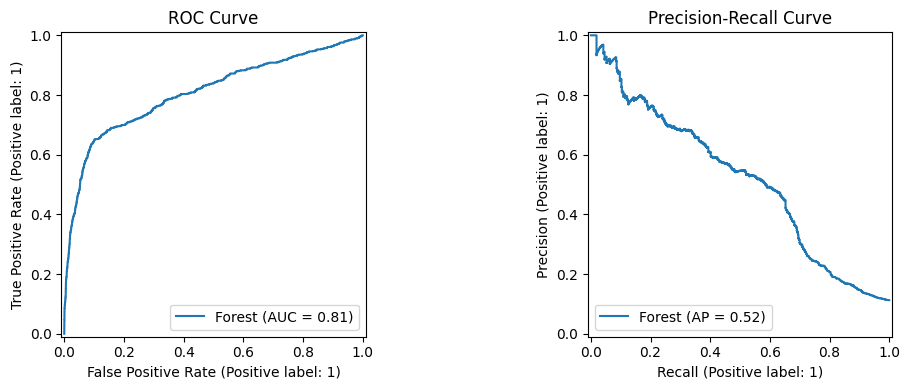

In [38]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
    ConfusionMatrixDisplay
)

final_pipe.fit(X_tr, y_tr)

# Use probabilities because the final model must support predict_proba.
if not hasattr(final_pipe, "predict_proba"):
    raise ValueError(
        "Choose a model with predict_proba for this final evaluation."
    )

hold_scores = final_pipe.predict_proba(X_hold)[:, 1]

print("Hold-out ROC-AUC:", round(
    roc_auc_score(y_hold, hold_scores), 4
))
print("Hold-out AP:", round(
    average_precision_score(y_hold, hold_scores), 4
))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

RocCurveDisplay.from_predictions(
    y_hold, hold_scores, ax=ax[0], name=final_name
)
ax[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_hold, hold_scores, ax=ax[1], name=final_name
)
ax[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

Clients called: 658 of 6588
Precision: 0.5456
Recall: 0.4838
Base yes rate: 0.1126
Lift: 4.84


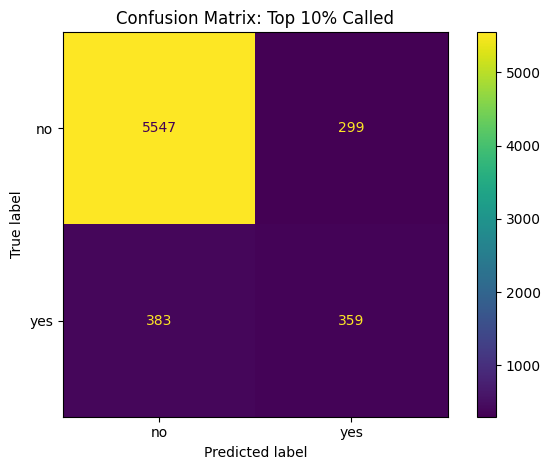

True positives: 359
False positives: 299
False negatives: 383
True negatives: 5547


In [39]:
# 10% capacity rule
from sklearn.metrics import precision_score, recall_score

n_call = max(1, int(0.10 * len(y_hold)))

# Select exactly the top 10% by score.
top_indices = np.argsort(hold_scores)[::-1][:n_call]

y_call = np.zeros(len(y_hold), dtype=int)
y_call[top_indices] = 1

precision = precision_score(y_hold, y_call, zero_division=0)
recall = recall_score(y_hold, y_call, zero_division=0)

base_rate = y_hold.mean()
lift = precision / base_rate if base_rate > 0 else np.nan

print("Clients called:", y_call.sum(), "of", len(y_hold))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Base yes rate:", round(base_rate, 4))
print("Lift:", round(lift, 2))

cm = confusion_matrix(y_hold, y_call, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["no", "yes"]
).plot()

plt.title("Confusion Matrix: Top 10% Called")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print("True negatives:", tn)

What the Results Mean for the Call Centre

The call centre contacts the top 10% of clients. Out of these clients, **[TP]** say yes and **[FP]** say no.

The model misses **[FN]** clients who would say yes because they are not in the selected group. The lift is **[value]**, which means that the selected clients are more likely to say yes than a random group of the same size.

These results show how the model can help the bank use its limited calling time.

## Stage 13: Saving the Model and Predictions

After the final evaluation, I fit the selected pipeline on all training data. This allows the model to learn from more examples.

I save the fitted pipeline as `model.joblib`. I use it to score every row in `test.csv`.

The predictions file has three columns: `id`, `y_pred` and `y_score`. The value `y_pred` is 1 for the top 10% of clients and 0 for the other clients.

In [40]:
import joblib
import os
from sklearn.base import clone

# Fit the chosen model on all labelled training data.
final_pipe_all = clone(final_pipe)
final_pipe_all.fit(X, y)

joblib.dump(final_pipe_all, "model.joblib")

# Keep the test columns in the same order as during training.
X_test = test[feature_cols].copy()

test_score = final_pipe_all.predict_proba(X_test)[:, 1]

# Select exactly the top 10% of test clients.
n_call_test = max(1, int(0.10 * len(test)))

top_test_indices = np.argsort(test_score)[::-1][:n_call_test]

test_pred = np.zeros(len(test), dtype=int)
test_pred[top_test_indices] = 1

pred = pd.DataFrame({
    "id": test["id"],
    "y_pred": test_pred,
    "y_score": test_score
})

pred.to_csv("predictions.csv", index=False)

print("Prediction shape:", pred.shape)
print("All IDs preserved:", pred["id"].equals(test["id"]))
print("Missing values:\n", pred.isna().sum())
print("Unique y_pred values:", sorted(pred["y_pred"].unique()))
print("Selected clients:", pred["y_pred"].sum())
print("Expected top 10%:", n_call_test)

print("Model size in MB:", round(
    os.path.getsize("model.joblib") / 1_000_000, 2
))

display(pred.head())

Prediction shape: (8236, 3)
All IDs preserved: True
Missing values:
 id         0
y_pred     0
y_score    0
dtype: int64
Unique y_pred values: [np.int64(0), np.int64(1)]
Selected clients: 823
Expected top 10%: 823
Model size in MB: 12.87


,id,y_pred,y_score
0,32940,0,0.040166
1,32941,0,0.040164
2,32942,0,0.051508
3,32943,0,0.081271
4,32944,0,0.046736
